# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Rayhan Alif Zahrandhika Rizqullah
- **Email:** rayhanalif5@gmail.com
- **ID Dicoding:** rayhan_alif_6Enz

---

## Menentukan Pertanyaan Bisnis

Tujuan analisis ini adalah untuk memahami bagaimana faktor operasional dan cuaca memengaruhi tingkat penggunaan layanan penyewaan sepeda harian. Dua pertanyaan utama yang akan dijawab meliputi:

1. **Pertanyaan 1:** Bagaimana perbandingan rata-rata penyewaan sepeda harian antara hari kerja (*workingday*) dan hari libur/akhir pekan pada setiap musim di tahun 2012?
2. **Pertanyaan 2:** Bagaimana pola sebaran jumlah penyewaan sepeda harian berdasarkan kelompok suhu udara (*temp_category*) pada rentang tahun 2011–2012?

## Import All Packages/Libraries

Mengimpor seluruh library yang dibutuhkan untuk pemrosesan data, manipulasi array, serta pembuatan grafik visualisasi.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

## Data Wrangling

Tahap ini mencakup pengumpulan data dari file CSV, pemeriksaan kualitas data untuk mendeteksi masalah (*missing values*, duplikat, dan ketidaksesuaian tipe data), serta pembersihan data.

### Gathering Data
Memuat dataset `day.csv` ke dalam DataFrame `day_df`.

In [3]:
# Gathering Data
import os

# Menggunakan path relatif agar aman di mana pun notebook dijalankan
data_path = os.path.join('data', 'day.csv') if os.path.exists(os.path.join('data', 'day.csv')) else 'day.csv'
day_df = pd.read_csv(data_path)

# Menampilkan 5 baris pertama data
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


### Assessing Data
Mengecek struktur data, keterisian kolom, tingkat duplikasi, serta gambaran nilai statistik awal dari variabel-variabel yang ada.

In [4]:
# Assessing Data
print("=== Informasi Tipe Data ===")
print(day_df.info())

print("\n=== Jumlah Missing Values ===")
print(day_df.isna().sum())

print("\n=== Jumlah Data Duplikat ===")
print("Duplikasi:", day_df.duplicated().sum())

print("\n=== Ringkasan Statistik Deskriptif ===")
print(day_df.describe())

=== Informasi Tipe Data ===
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB
None

=== Jumlah Missing Values ===
instant       0
dteday        0
season      

### Cleaning Data
Berdasarkan hasil asesmen, tidak ditemukan data hilang maupun duplikat. Namun, ada beberapa perbaikan format agar analisis lebih intuitif:
1. Mengubah kolom `dteday` ke tipe `datetime`.
2. Melakukan *mapping* kode numerik pada kolom `season` dan `workingday` menjadi teks eksplisit (*Spring*, *Summer*, *Fall*, *Winter*, serta *Hari Kerja* vs *Hari Libur / Akhir Pekan*).

In [6]:
# Cleaning Data
# 1. Konversi dteday ke datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])

# 2. Mapping label kategorikal
season_mapper = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
day_df['season_label'] = day_df['season'].map(season_mapper)

workingday_mapper = {0: 'Hari Libur / Akhir Pekan', 1: 'Hari Kerja'}
day_df['workingday_label'] = day_df['workingday'].map(workingday_mapper)

# Cek hasil perbaikan
day_df[['dteday', 'season_label', 'workingday_label']].head()

,dteday,season_label,workingday_label
0,2011-01-01,Spring,Hari Libur / Akhir Pekan
1,2011-01-02,Spring,Hari Libur / Akhir Pekan
2,2011-01-03,Spring,Hari Kerja
3,2011-01-04,Spring,Hari Kerja
4,2011-01-05,Spring,Hari Kerja


## Exploratory Data Analysis (EDA)

Pada tahap eksplorasi data, kita mengeksplorasi data untuk menjawab **kedua pertanyaan bisnis** yang telah didefinisikan sebelumnya.

In [7]:
# EDA Pertanyaan 1: Rata-rata penyewaan sepeda berdasarkan Musim dan Tipe Hari pada Tahun 2012
df_2012 = day_df[day_df['yr'] == 1]
print("=== EDA Pertanyaan 1: Rata-rata Penyewaan per Musim & Tipe Hari (2012) ===")
print(df_2012.groupby(['season_label', 'workingday_label'])['cnt'].agg(['mean', 'median', 'std', 'min', 'max']))

print("\n" + "="*60 + "\n")

# EDA Pertanyaan 2: Binning kategori suhu dan distribusi penyewaan
bins = [0, 0.3, 0.6, 1.0]
labels = ['Dingin', 'Sedang', 'Panas']
day_df['temp_category'] = pd.cut(day_df['temp'], bins=bins, labels=labels)

print("=== EDA Pertanyaan 2: Rata-rata & Statistik Penyewaan Berdasarkan Kategori Suhu (2011-2012) ===")
print(day_df.groupby('temp_category', observed=False)['cnt'].agg(['mean', 'median', 'std', 'min', 'max', 'count']))

=== EDA Pertanyaan 1: Rata-rata Penyewaan per Musim & Tipe Hari (2012) ===
                                              mean  median          std   min  \
season_label workingday_label                                                   
Fall         Hari Kerja                7005.600000  7112.0   726.505867  4073   
             Hari Libur / Akhir Pekan  6417.758621  6299.0  1145.972751  4459   
Spring       Hari Kerja                3797.416667  3807.0  1199.997984   441   
             Hari Libur / Akhir Pekan  3016.225806  2732.0  1465.846916  1013   
Summer       Hari Kerja                6149.171875  6253.0  1078.265061  2843   
             Hari Libur / Akhir Pekan  6347.357143  6594.5  1512.062369  1027   
Winter       Hari Kerja                5891.639344  5668.0  1495.055495    22   
             Hari Libur / Akhir Pekan  5574.500000  5530.0  1813.754455  2277   

                                        max  
season_label workingday_label                
Fall         Hari Kerj

### Export Cleaned Data
Menyimpan data hasil pembersihan ke dalam file `main_data.csv` yang nantinya akan dibaca oleh aplikasi dashboard Streamlit.

In [8]:
# Simpan data yang sudah dibersihkan ke file main_data.csv
day_df.to_csv('main_data.csv', index=False)
print("Berhasil membuat main_data.csv!")

Berhasil membuat main_data.csv!


## Visualization & Explanatory Analysis

Berikut adalah visualisasi data untuk menjawab masing-masing pertanyaan bisnis secara spesifik.

### Pertanyaan 1: Rata-rata Penyewaan Sepeda per Musim & Tipe Hari (Tahun 2012)
Grafik di bawah membandingkan volume penyewaan pada hari kerja versus hari libur di keempat musim sepanjang tahun 2012.

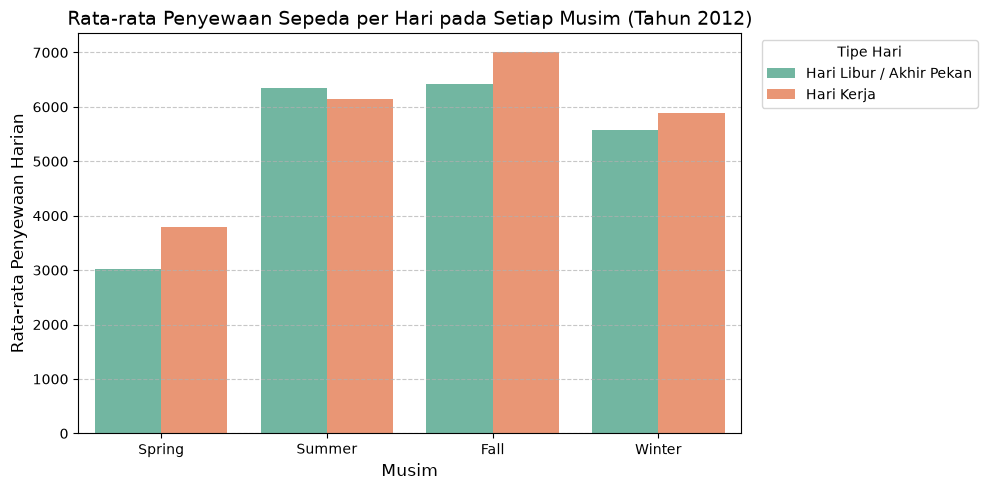

In [9]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=df_2012,
    x='season_label',
    y='cnt',
    hue='workingday_label',
    palette='Set2',
    errorbar=None
)
plt.title('Rata-rata Penyewaan Sepeda per Hari pada Setiap Musim (Tahun 2012)', fontsize=14)
plt.xlabel('Musim', fontsize=12)
plt.ylabel('Rata-rata Penyewaan Harian', fontsize=12)
plt.legend(title='Tipe Hari', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Distribusi Penyewaan Sepeda Berdasarkan Kategori Suhu Udara (2011–2012)
Grafik boxplot di bawah menunjukkan variasi dan sebaran jumlah penyewaan sepeda harian di setiap kelompok suhu udara.

C:\Users\rayha\AppData\Local\Temp\ipykernel_25220\888674507.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


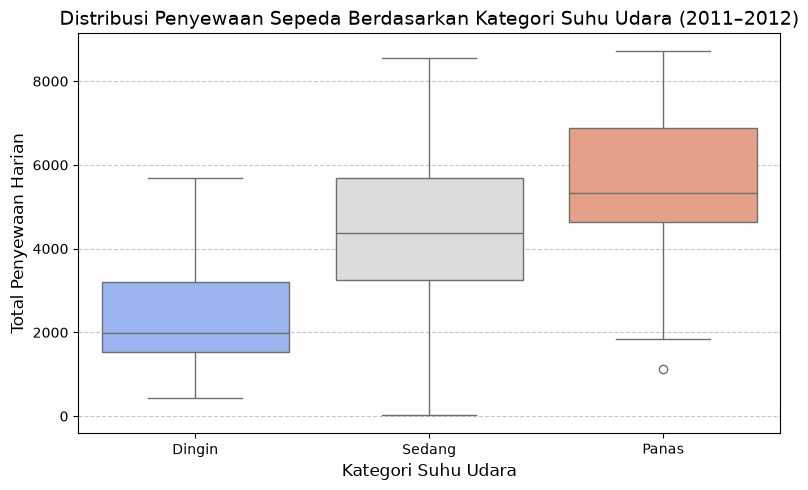

In [10]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=day_df,
    x='temp_category',
    y='cnt',
    palette='coolwarm'
)
plt.title('Distribusi Penyewaan Sepeda Berdasarkan Kategori Suhu Udara (2011–2012)', fontsize=14)
plt.xlabel('Kategori Suhu Udara', fontsize=12)
plt.ylabel('Total Penyewaan Harian', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Conclusion & Recommendation

### Kesimpulan

1. **Kesimpulan Pertanyaan 1:** 
   Pada tahun 2012, rata-rata penyewaan sepeda paling tinggi terjadi pada musim **Fall (Gugur)** dengan rata-rata **7.005,6 unit/hari** pada hari kerja dan **6.417,8 unit/hari** pada hari libur/akhir pekan. Posisi berikutnya ditempati oleh musim **Summer (Panas)** dengan rata-rata **6.149,2 unit/hari** pada hari kerja dan **6.347,4 unit/hari** pada hari libur, serta musim **Winter (Dingin)** sebesar **5.891,6 unit/hari** pada hari kerja dan **5.574,5 unit/hari** pada hari libur. Penyewaan terendah terjadi pada musim **Spring (Semi)** yaitu **3.797,4 unit/hari** (hari kerja) dan **3.016,2 unit/hari** (hari libur). Secara umum, penggunaan sepeda pada hari kerja cenderung lebih tinggi dibandingkan hari libur/akhir pekan di hampir seluruh musim, menunjukkan fungsi utama sepeda sebagai transportasi komuter harian.

2. **Kesimpulan Pertanyaan 2:** 
   Suhu udara berbanding lurus dengan tingkat penggunaan sepeda harian. Kategori suhu **Panas** (>0.6) mencatatkan rata-rata penyewaan tertinggi yaitu sebesar **5.654,6 unit/hari** (dengan nilai tengah/median **5.339 unit/hari** dan puncak maksimum **8.714 unit/hari**). Kategori suhu **Sedang** (0.3 - 0.6) mencatatkan rata-rata **4.488,2 unit/hari**. Sementara itu, kategori suhu **Dingin** (<0.3) mengalami penurunan signifikan dengan rata-rata penyewaan hanya sebesar **2.381,2 unit/hari**.

### Action Items / Rekomendasi
- **Penambahan Unit Armada:** Mengalokasikan lebih banyak unit sepeda di stasiun-stasiun sekitar kawasan perkantoran dan pusat transportasi umum pada hari kerja di Musim Panas dan Musim Gugur.
- **Jadwal Pemeliharaan Rutin (*Maintenance*):** Memanfaatkan Musim Dingin (periode dengan tingkat penyewaan paling rendah) untuk melakukan perbaikan dan perawatan besar-besaran pada armada sepeda agar kondisi unit optimal saat memasuki musim puncak.